In [15]:
import torch
from torch.autograd import Variable
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(2,1,bias=False)
    def forward(self, x):
        x = self.fc1(x)
        return x

net = Net()
print(net)


net.fc1.weight = torch.nn.Parameter(torch.tensor([[1., -1.]], requires_grad=True))

print(list(net.parameters()))

#input = torch.randn(1,2)
#out = net(input)


criterion = nn.MSELoss()
#def criterion(out, label):
#    return ((label - out)**2).mean()


optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.5)
#optimizer = optim.Adam(net.parameters(), lr=0.005)


data = torch.tensor([[1.,3.], [2.,6.], [3.,9.]], dtype=torch.float)
target = torch.tensor([[1.],[5.],[13.]], dtype=torch.float)

hist = []



Net(
  (fc1): Linear(in_features=2, out_features=1, bias=False)
)
[Parameter containing:
tensor([[ 1., -1.]], requires_grad=True)]


Epoch 0 - loss: 150.3333282470703
Epoch 1 - loss: 6.120000839233398
Epoch 2 - loss: 36.42483139038086
Epoch 3 - loss: 18.104551315307617
Epoch 4 - loss: 6.065778732299805
Epoch 5 - loss: 10.36883544921875
Epoch 6 - loss: 6.232231140136719
Epoch 7 - loss: 5.852262020111084
Epoch 8 - loss: 6.088119983673096
Epoch 9 - loss: 5.494865417480469
Epoch 10 - loss: 5.574592590332031
Epoch 11 - loss: 5.536749362945557
Epoch 12 - loss: 5.476495265960693
Epoch 13 - loss: 5.4938530921936035
Epoch 14 - loss: 5.480627536773682
Epoch 15 - loss: 5.477013111114502
Epoch 16 - loss: 5.478647232055664
Epoch 17 - loss: 5.476378917694092
Epoch 18 - loss: 5.476480007171631
Epoch 19 - loss: 5.476463794708252
Epoch 20 - loss: 5.476191997528076
Epoch 21 - loss: 5.476251602172852
Epoch 22 - loss: 5.4762139320373535
Epoch 23 - loss: 5.476190567016602
Epoch 24 - loss: 5.476198673248291
Epoch 25 - loss: 5.476193904876709
Epoch 26 - loss: 5.476190567016602
Epoch 27 - loss: 5.476190567016602
Epoch 28 - loss: 5.47619056

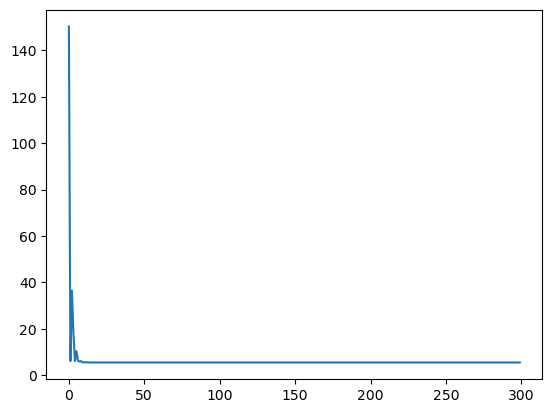

In [16]:
############## Batch GD based update ##############       
      
for epoch in range(300):   
    optimizer.zero_grad()
    outputs = net(data)
    loss = criterion(outputs, target)
    loss.backward()
    hist.append(loss.detach())
    optimizer.step()
    print("Epoch {} - loss: {}".format(epoch, loss))
####################################################

### Test the trained network ###
for i, current_data in enumerate(data):
    out = net(current_data)  
    print("when x = {}, y = {}".format(current_data, out))
    
plt.plot(hist, label = "training curve")

Net(
  (fc1): Linear(in_features=2, out_features=1, bias=False)
)
[Parameter containing:
tensor([[ 1., -1.]], requires_grad=True)]
Epoch 0 - loss: 9.0
Epoch 0 - loss: 60.840003967285156
Epoch 0 - loss: 48.16359329223633
Epoch 1 - loss: 47.52723693847656
Epoch 1 - loss: 193.33233642578125
Epoch 1 - loss: 1.0173128843307495
Epoch 2 - loss: 0.45298048853874207
Epoch 2 - loss: 24.202863693237305
Epoch 2 - loss: 88.83402252197266
Epoch 3 - loss: 41.247581481933594
Epoch 3 - loss: 182.4311065673828
Epoch 3 - loss: 1.685847282409668
Epoch 4 - loss: 0.5527670979499817
Epoch 4 - loss: 23.358642578125
Epoch 4 - loss: 89.11278533935547
Epoch 5 - loss: 40.98900604248047
Epoch 5 - loss: 181.1503143310547
Epoch 5 - loss: 1.635256290435791
Epoch 6 - loss: 0.573534369468689
Epoch 6 - loss: 22.94943618774414
Epoch 6 - loss: 88.66230010986328
Epoch 7 - loss: 40.82246398925781
Epoch 7 - loss: 180.02647399902344
Epoch 7 - loss: 1.5735151767730713
Epoch 8 - loss: 0.5932254791259766
Epoch 8 - loss: 22.55220

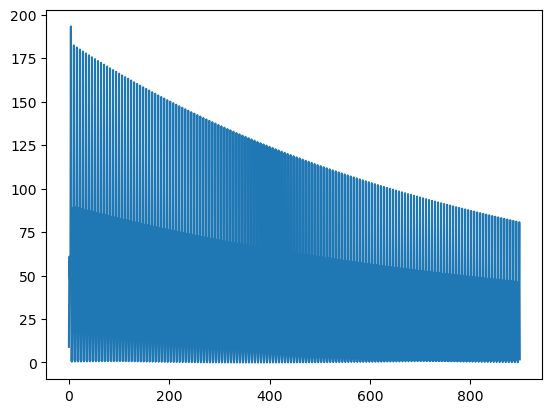

In [17]:
net = Net()
print(net)


net.fc1.weight = torch.nn.Parameter(torch.tensor([[1., -1.]], requires_grad=True))

print(list(net.parameters()))

#input = torch.randn(1,2)
#out = net(input)


criterion = nn.MSELoss()
#def criterion(out, label):
#    return ((label - out)**2).mean()


optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.5)
#optimizer = optim.Adam(net.parameters(), lr=0.005)


data = torch.tensor([[1.,3.], [2.,6.], [3.,9.]], dtype=torch.float)
target = torch.tensor([[1.],[5.],[13.]], dtype=torch.float)

hist = []

############## SGD (non batch) based update ##############       
      
for epoch in range(300):   
    for i, current_data in enumerate(data):
        X1, X2 = current_data
        X = torch.FloatTensor([X1, X2])
        optimizer.zero_grad()
        output = net(X)
        loss = criterion(output, target[i])
        loss.backward()
        hist.append(loss.detach())
        optimizer.step()
        print("Epoch {} - loss: {}".format(epoch, loss))
    ####################################################

### Test the trained network ###
for i, current_data in enumerate(data):
    out = net(current_data)  
    print("when x = {}, y = {}".format(current_data, out))

plt.figure()
plt.plot(hist, label = "training curve")

6. Download “[HW_Code4]_Perceptron_batch_vs_SGD.ipynb". The current code uses batch-based training (10 pts).
Modify code to replace the batch-based training with Stochastic Gradient Descent (SGD) training (i.e. gradient update must happen after each data point)
What differences do you observe in the training behavior (e.g., noisy vs. smooth loss curve)? Why do you think this happens? Explain based on your intuition.

The batch version is smooth and gets low loss quickly while the SGD version is noisy with a lot of increase and decrease of the loss. This makes sense since the batch will train the net on all the data we have supplied so it will be trained to be closer to the target. The SGD version will update for each data point, so the model will get trained to specific data points which may make the loss worse for the other data points.